# Task 05 — Mobile-money fraud: does a model beat the legacy rule at the same review budget?

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [Synthetic Financial Datasets For Fraud Detection (PaySim)](https://www.kaggle.com/datasets/ealaxi/paysim1) (a month of simulated mobile-money transactions, calibrated on the logs of a real service in an African country; López-Rojas, Elmir and Axelsson, 2016)
**Task family:** tabular supervised learning with graph context, comparison with a legacy rule at a fixed review budget, drift on a time axis · **Companion task:** `02_card_fraud_tabular.ipynb` (honest evaluation of card fraud); `01_aml_graph_triage.ipynb` for the graph side

---

## The task card

> **Board question.** *Our fraud desk can review 200 alerts a day. Over the last six days of the month the provider's rule (`isFlaggedFraud`) raised 6 alerts and caught 0.4 % of fraudulent transactions; tightened to fill 200 a day, it would catch 12 %. Does a model catch more at the same 200 a day, and does the answer survive without the balance columns the dataset's authors forbid?*

**Business context.** A mobile-money operator keeps a wallet on each customer's phone: people pay merchants, send money to each other, and swap cash for e-money at agents. The fraud here is account takeover: the fraudster empties a victim's wallet by TRANSFER to a mule, who cashes it out at an agent within the hour. The core platform, the legacy estate, already runs a hard-coded rule against large transfers. A model would sit beside it in the authorisation path (Session 01's *online prediction* pattern) and hold suspicious transactions for a review desk (*human-in-the-loop*); a nightly batch would be too late.

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given **transaction-scoring model**, packaged and reproducible, evaluated forward in time and compared with the legacy rule **at the same review budget**, with the traps guarded by tests;
2. **who-pays-whom context**, with its ablation;
3. an **operating point** from the desk's capacity, as an ADR;
4. the **operational wrapper**: package, container, CI gate, registry, model card, monitoring plan;
5. a one-page **recommendation to the head of fraud**.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Online scoring beside a legacy rule; hold and review; AI Act position |
| 2 · MLOps | Forward split by hour, gate on precision at budget, leakage test, traffic drift (S04), registry (S06) |
| 3 · Semantic layer | Who-pays-whom graph, transaction-type ontology; the mule link as entity resolution |
| 4 · LLM/RAG | Investigator case note grounded in the transfer chain (S10–S11) |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. The notebook contains **deliberate traps**, each flagged with ⚠ in the text; turning each into a test is part of the task.

**Honesty note.** The data is **synthetic**: PaySim, an agent-based simulator, generated it from aggregates of a real service's logs. Types, amounts and the busy days' rhythm come from those logs; the fraud comes from the simulator's own agent, whose artefacts are measured below: it never sleeps, always empties the account, and cashes out the stolen amount to the cent. Treat the numbers as evidence about method, not about mobile-money fraud.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card and first look, with the legacy rule | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–6 | As-of and who-pays-whom features, training forward in time against the rule, the operating point, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 7–10 | The model after deployment, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 7 shows the drift your monitoring must catch. |

**What you need from Parts A and B**

- **Code to package:** `get_raw` and `load_paysim` (Section 1); the as-of feature construction (Section 3); `fit_eval`, `precision_at_k` and `per_day_for` (Section 4); `chain_view` (Section 5); `psi` and `psi_shares` for monitoring (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** train 2,615,822 rows (266,352 after sampling, 4,589 fraud), validation 86,634 (1,784 fraud) and holdout 67,657 (1,544 fraud, steps 577–718); AUPRC 0.914 on the holdout; at the budget of k = 1,183 alerts the queue is 93.6 % fraud against 16.2 % for the tightened rule; threshold 0.616, giving 204 alerts a day at precision 92.9 % and recall 72.6 %.
- **Runtime:** about 3 minutes on a laptop (186 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
import os, json, time, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import pyarrow as pa
import pyarrow.csv as pacsv
import pyarrow.compute as pc
import lightgbm as lgb
import networkx as nx
import sklearn
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*does not have valid feature names.*")
pd.set_option("display.width", 140)

# ---- parameters -------------------------------------------------------------
SEED = 3217
KAGGLE_HANDLE = "ealaxi/paysim1"
CSV_FILE = "PS_20174392719_1491204439457_log.csv"
LAST_STEP = 718             # last hour with any legitimate traffic; steps 719–743 are fraud only (quirk 3)
TRAIN_END = 408             # train: steps 1–408 (days 1–17)
VALID_END = 576             # validation, used only to set the threshold: steps 409–576 (days 18–24)
                            # holdout, frozen: steps 577–718 (days 25–30)
SCORED_TYPES = ["TRANSFER", "CASH_OUT"]   # the only types with fraud in this data (quirk 2)
NEG_SAMPLE = 0.10           # share of legitimate training rows kept (speed only; every fraud kept; evaluation untouched)
REVIEW_BUDGET_PER_DAY = 200 # alerts the fraud desk can review a day (assumption: vary it in task C3)
REVIEW_COST = 1_000         # cost of one review, in the data's currency units (assumption: task C3)
LEGACY_THRESHOLD = 200_000  # the documented legacy rule: a TRANSFER above this amount is an illegal attempt
N_JOBS = 1                  # threads per model; raise it on your own laptop

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "paysim", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
np.random.seed(SEED)
T_START = time.time()
print(f"pandas {pd.__version__} · lightgbm {lgb.__version__} · networkx {nx.__version__} · "
      f"scikit-learn {sklearn.__version__} · numpy {np.__version__}")

pandas 3.1.0 · lightgbm 4.7.0 · networkx 3.7 · scikit-learn 1.9.1 · numpy 2.5.4


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw` and `load_paysim`.*

| Field | Value |
|---|---|
| **Source** | Kaggle: `ealaxi/paysim1` (Edgar Lopez-Rojas), output of the PaySim simulator |
| **Licence** | CC BY-SA 4.0: share-alike, so derived data carries the same licence |
| **Provenance** | Synthetic: PaySim (López-Rojas, Elmir and Axelsson, 2016), calibrated on one month of a real mobile-money service's logs |
| **Size** | 6,362,620 transactions, 11 columns; 494 MB as CSV, 356 MB in memory once typed |
| **Files** | `PS_20174392719_1491204439457_log.csv` |
| **Schema** | `step` (hour 1–743), `type` (CASH_IN, CASH_OUT, DEBIT, PAYMENT, TRANSFER), `amount`, `nameOrig`, `nameDest`, four balance columns (sender and receiver, before and after), `isFraud`, `isFlaggedFraud` |
| **Label** | `isFraud`: 8,213 transactions (0.129 %). `isFlaggedFraud`, the provider's rule: 16 |
| **Window used here** | Steps 1–718, TRANSFER and CASH_OUT (2.77 M rows): train 1–408 (days 1–17), threshold 409–576 (days 18–24), frozen holdout 577–718 (days 25–30). Training keeps every fraud and a seeded 10 % of legitimate rows. Peak memory about 2 GB (2.3 GB on the first run); on a small laptop, cache only the scored types |
| **PII** | None: synthetic names (`C…` customers, `M…` merchants), replaced on load by integer surrogate keys plus a merchant flag; a production feed would use a keyed hash |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **The balance columns leak the label.** The authors' note says fraudulent transactions are cancelled, so the four balance columns must not be used. On the holdout, "amount equals the sender's opening balance" alone is 100 % fraud and finds 97.0 % of it (Trap 1).
2. ⚠ **Fraud lives in two types.** All 8,213 frauds are TRANSFER or CASH_OUT, and `M…` receivers appear only on PAYMENT, so the `nameDest` prefix is the type by another name. Scoring only the two types leaves a new path through PAYMENT unseen (Section 7 simulates a related blind spot).
3. ⚠ **Legitimate traffic switches off; fraud does not.** Fraud runs at about 262 a day, every day; legitimate traffic at 349 k–574 k a day on days 1–2 and 6–17, and 760–57,613 on days 3–5 and 18–30. 320 of the 743 hours hold no legitimate transaction; steps 719–743 are fraud only (Traps 3–4, Section 7).
4. **The chain is linked by amount and hour, not by account.** 99.5 % of fraudulent TRANSFERs are followed in the next row by a fraudulent CASH_OUT of the same amount, from a *different* account than the receiver.
5. **Senders have no history** (6,353,307 distinct senders in 6.36 M rows); the history lives with the 2,722,362 receivers.
6. ⚠ **`isFlaggedFraud` is not the documented rule.** The documented rule (TRANSFER above 200,000) fires on 409,110 transactions at 0.67 % precision. The column fires 16 times, all fraud, and equals "TRANSFER above 200,000 whose sender's balance did not move": a record of blocked transfers, computed from the forbidden columns.
7. **743 steps, not 744**; fraudulent transactions are capped at 10,000,000.

In [2]:
def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

COLUMN_TYPES = {"step": pa.int16(), "type": pa.dictionary(pa.int32(), pa.string()), "amount": pa.float64(),
                "nameOrig": pa.string(), "oldbalanceOrg": pa.float64(), "newbalanceOrig": pa.float64(),
                "nameDest": pa.string(), "oldbalanceDest": pa.float64(), "newbalanceDest": pa.float64(),
                "isFraud": pa.int8(), "isFlaggedFraud": pa.int8()}
BALANCES = ["oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]

def load_paysim() -> pd.DataFrame:
    cache = PROCESSED / "05_paysim.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    t = time.time()
    tbl = pacsv.read_csv(get_raw(CSV_FILE), convert_options=pacsv.ConvertOptions(column_types=COLUMN_TYPES))
    # ---- governance on load: account names become integer surrogate keys; the names never leave this function ----
    def account_key(col):
        name = tbl[col]
        is_merchant = np.asarray(pc.equal(pc.utf8_slice_codeunits(name, 0, 1), "M"))
        number = np.asarray(pc.cast(pc.utf8_slice_codeunits(name, 1), pa.int64()))
        return number * 2 + is_merchant, is_merchant
    k_orig, m_orig = account_key("nameOrig")
    k_dest, m_dest = account_key("nameDest")
    assert not m_orig.any(), "a merchant appears as a sender"
    codes, _ = pd.factorize(np.concatenate([k_orig, k_dest]))   # one key space for senders and receivers
    n = tbl.num_rows
    df = pd.DataFrame({"step": np.asarray(tbl["step"]), "type": tbl["type"].to_pandas().astype("category"),
                       "amount": np.asarray(tbl["amount"]),
                       "orig": codes[:n].astype(np.int32), "dest": codes[n:].astype(np.int32),
                       "dest_is_merchant": m_dest,
                       **{c: np.asarray(tbl[c]) for c in BALANCES},
                       "isFraud": np.asarray(tbl["isFraud"]), "isFlaggedFraud": np.asarray(tbl["isFlaggedFraud"])})
    del tbl, k_orig, k_dest, codes
    df.to_parquet(cache)
    print(f"loaded + cached in {time.time()-t:.0f}s")
    return df

tx = load_paysim()
assert tx.step.is_monotonic_increasing          # rows are in time order: every as-of feature below relies on it
tx["hour"] = ((tx.step - 1) % 24).astype(np.int8)
tx["day"] = ((tx.step - 1) // 24 + 1).astype(np.int8)
print(f"{len(tx):,} transactions · steps {tx.step.min()}–{tx.step.max()} ({tx.step.nunique()} hours, {tx.day.nunique()} days) · "
      f"{int(tx.isFraud.sum()):,} fraud ({tx.isFraud.mean():.3%}) · {int(tx.isFlaggedFraud.sum())} flagged by the legacy rule · "
      f"{tx.orig.nunique():,} senders · {tx.dest.nunique():,} receivers · {tx.memory_usage(deep=True).sum()/1e6:.0f} MB")
tx.head(3)

6,362,620 transactions · steps 1–743 (743 hours, 31 days) · 8,213 fraud (0.129%) · 16 flagged by the legacy rule · 6,353,307 senders · 2,722,362 receivers · 356 MB


,step,type,amount,orig,dest,dest_is_merchant,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,hour,day
0,1,PAYMENT,9839.64,0,6353307,True,170136.0,160296.36,0.0,0.0,0,0,0,1
1,1,PAYMENT,1864.28,1,6353308,True,21249.0,19384.72,0.0,0.0,0,0,0,1
2,1,TRANSFER,181.00,2,6353309,False,181.0,0.00,0.0,0.0,1,0,0,1


## 2 · First look

*Part A · Explore · read; the legacy rule's three versions are the baseline every later number is compared with.*

What a fraud lead asks first: where the fraud is, when it happens, and what the existing rule does.

,n,fraud,flagged,median_amount,receiver_is_merchant,fraud rate
type,,,,,,
CASH_OUT,"2,237,500","4,116",0,"147,072",0%,0.184%
PAYMENT,"2,151,495",0,0,"9,482",100%,0.000%
CASH_IN,"1,399,284",0,0,"143,428",0%,0.000%
TRANSFER,"532,909","4,097",16,"486,308",0%,0.769%
DEBIT,"41,432",0,0,"3,049",0%,0.000%


hours with no legitimate transaction: 320 of 743 · last hour with legitimate traffic: step 718 · fraud per day: median 262 (min 216, max 320)
legitimate per day · busy days (1–2, 6–17): 349,478–573,984 · sparse days (3–5, 18–30): 760–57,613 · busy days carry 93.6% of legitimate traffic
largest fraudulent transaction: 10,000,000 · exactly 10,000,000: 287 fraud, 2,920 legitimate


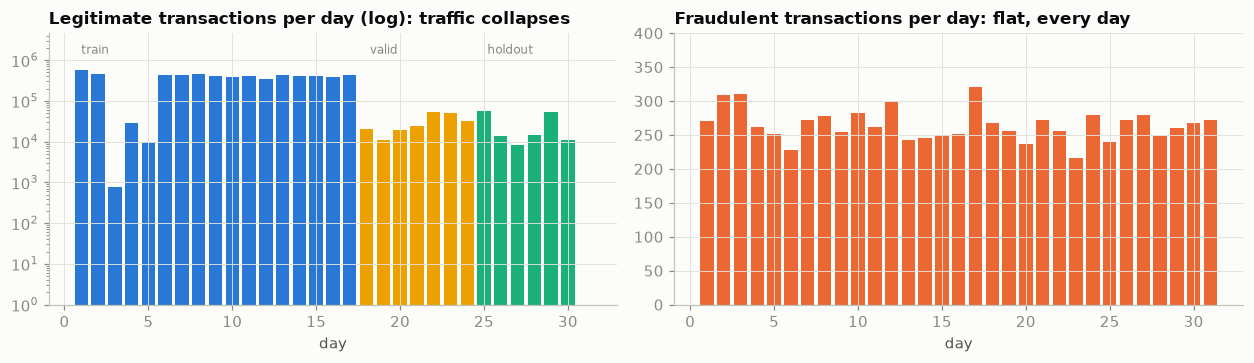

In [3]:
by_type = tx.groupby("type", observed=True).agg(n=("amount", "size"), fraud=("isFraud", "sum"), flagged=("isFlaggedFraud", "sum"),
                                                median_amount=("amount", "median"), receiver_is_merchant=("dest_is_merchant", "mean"))
by_type["fraud rate"] = by_type.fraud / by_type.n
display(by_type.sort_values("n", ascending=False).style.format(
    {"n": "{:,}", "fraud": "{:,}", "flagged": "{:,}", "median_amount": "{:,.0f}", "receiver_is_merchant": "{:.0%}", "fraud rate": "{:.3%}"}))

steps = tx.groupby("step").agg(n=("amount", "size"), fraud=("isFraud", "sum"))
steps["legit"] = steps.n - steps.fraud
daily = steps.groupby((steps.index - 1) // 24 + 1).agg(legit=("legit", "sum"), fraud=("fraud", "sum"))
busy = daily.index.isin([1, 2] + list(range(6, 18)))
sparse = ~busy & (daily.index <= 30)
print(f"hours with no legitimate transaction: {int((steps.legit == 0).sum())} of {len(steps)} · "
      f"last hour with legitimate traffic: step {steps.index[steps.legit > 0].max()} · "
      f"fraud per day: median {daily.fraud.median():.0f} (min {daily.fraud.min()}, max {daily.fraud.max()})")
print(f"legitimate per day · busy days (1–2, 6–17): {daily.legit[busy].min():,}–{daily.legit[busy].max():,} · "
      f"sparse days (3–5, 18–30): {daily.legit[sparse].min():,}–{daily.legit[sparse].max():,} · "
      f"busy days carry {daily.legit[busy].sum() / daily.legit.sum():.1%} of legitimate traffic")
print(f"largest fraudulent transaction: {tx.amount[tx.isFraud == 1].max():,.0f} · exactly 10,000,000: "
      f"{int(((tx.amount == 1e7) & (tx.isFraud == 1)).sum())} fraud, {int(((tx.amount == 1e7) & (tx.isFraud == 0)).sum()):,} legitimate")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.4))
ax = axes[0]
split_color = np.where(daily.index <= TRAIN_END // 24, SERIES[0], np.where(daily.index <= VALID_END // 24, SERIES[3], SERIES[2]))
ax.bar(daily.index, daily.legit.clip(lower=1), color=split_color, width=0.8)
ax.set_yscale("log"); ax.set_ylim(1, daily.legit.max() * 8)
for x, lab_ in [(1, "train"), (18.2, "valid"), (25.2, "holdout")]:
    ax.text(x, daily.legit.max() * 2.5, lab_, color=MUTED, fontsize=8)
ax.set_title("Legitimate transactions per day (log): traffic collapses"); ax.set_xlabel("day")
ax = axes[1]
ax.bar(daily.index, daily.fraud, color=SERIES[1], width=0.8)
ax.set_ylim(0, daily.fraud.max() * 1.25)
ax.set_title("Fraudulent transactions per day: flat, every day"); ax.set_xlabel("day")
plt.tight_layout()

Fraud lives only in TRANSFER (0.769 %) and CASH_OUT (0.184 %), and the simulator runs two clocks: legitimate traffic, busy for fourteen days (93.6 % of the volume), and a fraud agent that never stops. Validation and holdout fall in the sparse regime, where fraud is 2.06 % (validation) and 2.28 % (holdout) of scored transactions against 0.18 % in training, so their precision is not a busy day's.

In [4]:
# One fraud chain as it appears in the log: a TRANSFER and, in the next row, a CASH_OUT of the same amount
i = int(np.flatnonzero(((tx.type == "TRANSFER") & (tx.isFraud == 1) & (tx.step > VALID_END)).values)[0])
display(tx.iloc[i:i + 2][["step", "type", "amount", "orig", "dest"] + BALANCES + ["isFraud", "isFlaggedFraud"]])
fT = np.flatnonzero(((tx.type == "TRANSFER") & (tx.isFraud == 1)).values)
nxt = tx.iloc[fT + 1]
print(f"fraud TRANSFERs followed in the next row by a fraud CASH_OUT of the same amount: "
      f"{((nxt.type.values == 'CASH_OUT') & (nxt.isFraud.values == 1) & (nxt.amount.values == tx.amount.values[fT])).mean():.1%} · "
      f"of which the CASH_OUT comes from the account that received the TRANSFER: {(nxt.orig.values == tx.dest.values[fT]).mean():.1%}")

# What the legacy rule is on paper, and what the flag column records
documented = (tx.type == "TRANSFER") & (tx.amount > LEGACY_THRESHOLD)
reconstructed = documented & (tx.oldbalanceOrg > 0) & (tx.oldbalanceOrg == tx.newbalanceOrig)
print(f"documented rule (TRANSFER > {LEGACY_THRESHOLD:,}): {int(documented.sum()):,} transactions, "
      f"precision {tx.isFraud[documented].mean():.2%}, recall {tx.isFraud[documented].sum() / tx.isFraud.sum():.1%}")
print(f"isFlaggedFraud: {int(tx.isFlaggedFraud.sum())} transactions, all fraud: {bool(tx.isFraud[tx.isFlaggedFraud == 1].all())} · "
      f"'TRANSFER > {LEGACY_THRESHOLD:,} whose sender balance did not move' reproduces it: "
      f"{int((reconstructed & (tx.isFlaggedFraud == 1)).sum())} of {int(tx.isFlaggedFraud.sum())}, {int((reconstructed & (tx.isFlaggedFraud == 0)).sum())} extra")

,step,type,amount,orig,dest,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
6201209,577,TRANSFER,681525.62,6192344,9002386,681525.62,0.0,0.00,0.00,1,0
6201210,577,CASH_OUT,681525.62,6192345,8271914,681525.62,0.0,2250319.57,2931845.19,1,0


fraud TRANSFERs followed in the next row by a fraud CASH_OUT of the same amount: 99.5% · of which the CASH_OUT comes from the account that received the TRANSFER: 0.0%


documented rule (TRANSFER > 200,000): 409,110 transactions, precision 0.67%, recall 33.4%
isFlaggedFraud: 16 transactions, all fraud: True · 'TRANSFER > 200,000 whose sender balance did not move' reproduces it: 16 of 16, 0 extra


The pair above is the fraud in two rows: the victim's balance goes to zero, the transfer's receiving balances never move, and a *different* account cashes out the same 681,525.62. The balance columns describe the outcome, not the moment of decision.

The rule as recorded is 16 blocked transfers that no one can score at authorisation, so we compare three ways on the same window: the flags as recorded, the rule as documented, and the rule *tightened* until it fits 200 a day.

# Part B — The given model

*Sections 3–6: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · Features: the transaction, and who pays whom

*Part B · Given model · package the as-of features unchanged; C1 turns the as-of rule into a test, E1 ablates the graph context.*

One rule: **a feature may use only earlier rows** (the log is in time order). Two families:

- **Per-transaction**: type, amount, hour of day. No balances (Trap 1).
- **Who pays whom**: the receiver's history as running counts (earlier receipts, value received, hours since first seen), and the **chain link**: a CASH_OUT whose exact amount left by TRANSFER earlier in the same hour.

In production these are counters keyed by account in a feature store; `networkx` is for structure, below.

In [5]:
t0 = time.time()
# ---- as-of graph features: running counts over the receiver's earlier rows (rows are in time order) ----
g = tx.groupby("dest", sort=False)
tx["dest_prior_in"] = g.cumcount().astype(np.int32)                      # money received before this row
tx["dest_prior_amt"] = g.amount.cumsum() - tx.amount                      # value received before this row
tx["dest_age_steps"] = (tx.step - g.step.transform("min")).astype(np.int16)   # hours since the receiver first appeared
tx["dest_total_in"] = g.dest.transform("size").astype(np.int32)          # ⚠ whole-month count: uses the future (Trap 2)
# ---- the mule link: a CASH_OUT whose exact amount left by TRANSFER earlier in the same hour ----
key = tx.step.astype(np.int64) * 10**12 + np.round(tx.amount * 100).astype(np.int64)
is_T, is_C = (tx.type == "TRANSFER").values, (tx.type == "CASH_OUT").values
first_T = pd.Series(np.flatnonzero(is_T), index=key[is_T].values).groupby(level=0).min()
last_C = pd.Series(np.flatnonzero(is_C), index=key[is_C].values).groupby(level=0).max()
t_row, c_row, row = key.map(first_T).values, key.map(last_C).values, np.arange(len(tx))
tx["chain_back"] = (is_C & (t_row < row)).astype(np.int8)                # as-of: the transfer is already in the log
tx["chain_fwd"] = (is_T & (c_row > row)).astype(np.int8)                 # ⚠ look-ahead: the cash-out has not happened yet (Trap 2)
tx["t_partner"] = np.where(tx.chain_back == 1, t_row, -1).astype(np.int64)
tx["traffic_so_far"] = tx.groupby("step").cumcount().astype(np.int32)    # ⚠ the simulator's clock (Trap 3)
del g, key, first_T, last_C, t_row, c_row, row

BASE = ["type", "amount", "hour"]
RECEIVER = ["dest_prior_in", "dest_prior_amt", "dest_age_steps"]
CHAIN = ["chain_back"]
GRAPH = BASE + RECEIVER + CHAIN
print(f"features in {time.time()-t0:.1f}s")
sc_all = tx[tx.type.isin(SCORED_TYPES)]
summary = sc_all.groupby(["type", "isFraud"], observed=True).agg(
    rows=("amount", "size"), receiver_new=("dest_prior_in", lambda s: (s == 0).mean()),
    median_prior_receipts=("dest_prior_in", "median"), chain_link=("chain_back", "mean"), chain_link_n=("chain_back", "sum"))
del sc_all
summary.style.format({"rows": "{:,}", "receiver_new": "{:.1%}", "median_prior_receipts": "{:.0f}", "chain_link": "{:.2%}", "chain_link_n": "{:,}"})

features in 11.4s


Each family separates one leg. 99.9 % of fraudulent TRANSFERs go to a receiver that has never received money, against 11.5 % of legitimate ones: a fresh mule. 99.0 % of fraudulent CASH_OUTs carry the chain link, against 36 of 2.23 million legitimate ones. Neither needs the balances.

holdout window graph: 313,506 accounts · 161,130 edges · 152,376 weakly connected components, the largest has 6 accounts
fraud TRANSFER recipients that send anything onward: 0 of 772


inferred same-money links: 766 (fraud among them: 100.0%) · accounts reachable from a fraud victim: 1.00 without the links, 2.98 with them


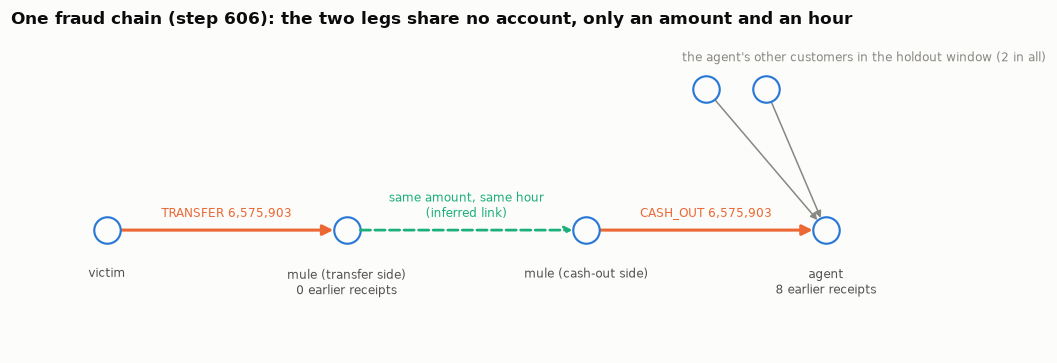

In [6]:
# The who-pays-whom graph of the holdout window, with networkx
win = tx[(tx.step > VALID_END) & (tx.step <= LAST_STEP)]
G = nx.DiGraph()
G.add_edges_from(zip(win.orig.values, win.dest.values))
wcc = sorted((len(c) for c in nx.weakly_connected_components(G)), reverse=True)
fraud_T = win[(win.isFraud == 1) & (win.type == "TRANSFER")]
print(f"holdout window graph: {G.number_of_nodes():,} accounts · {G.number_of_edges():,} edges · "
      f"{len(wcc):,} weakly connected components, the largest has {wcc[0]} accounts")
print(f"fraud TRANSFER recipients that send anything onward: {sum(G.out_degree(d) > 0 for d in fraud_T.dest.values)} of {len(fraud_T)}")

links = win[win.chain_back == 1]
mule = tx.dest.values[links.t_partner.values]
H = G.copy()
H.add_edges_from(zip(mule, links.orig.values))   # inferred 'same money' edges: mule (transfer side) → cash-out account
reach_G = np.mean([len(nx.descendants(G, v)) for v in fraud_T.orig.values])
reach_H = np.mean([len(nx.descendants(H, v)) for v in fraud_T.orig.values])
print(f"inferred same-money links: {len(links)} (fraud among them: {links.isFraud.mean():.1%}) · "
      f"accounts reachable from a fraud victim: {reach_G:.2f} without the links, {reach_H:.2f} with them")

# draw one chain whose agent also serves other customers in the window
cand = links[links.isFraud == 1]
agent_deg = np.array([G.in_degree(int(a)) for a in cand.dest.values])
c = cand.iloc[int(np.argmin(np.abs(agent_deg - 6)))]
tr_row = tx.iloc[int(c.t_partner)]
victim, mule_a, cash_a, agent = int(tr_row.orig), int(tr_row.dest), int(c.orig), int(c.dest)
others = [u for u in G.predecessors(agent) if u != cash_a][:5]
pos = {victim: (0, 0), mule_a: (1, 0), cash_a: (2, 0), agent: (3, 0)}
pos.update({u: (2.5 + 0.25 * j, 0.75) for j, u in enumerate(others)})
fig, ax = plt.subplots(figsize=(10, 3.4))
nx.draw_networkx_nodes(G.subgraph(pos), pos, ax=ax, node_size=300, node_color="#fcfcfb", edgecolors=SERIES[0], linewidths=1.4)
nx.draw_networkx_edges(G, pos, edgelist=[(u, agent) for u in others], ax=ax, edge_color=MUTED, width=1, arrowsize=9)
nx.draw_networkx_edges(G, pos, edgelist=[(victim, mule_a), (cash_a, agent)], ax=ax, edge_color=SERIES[1], width=2, arrowsize=14)
ax.annotate("", xy=pos[cash_a], xytext=pos[mule_a], arrowprops=dict(arrowstyle="->", ls="--", color=SERIES[2], lw=1.8, shrinkA=9, shrinkB=9))
labels = {victim: "victim", mule_a: f"mule (transfer side)\n{int(tr_row.dest_prior_in)} earlier receipts",
          cash_a: "mule (cash-out side)", agent: f"agent\n{int(c.dest_prior_in)} earlier receipts"}
for n_, (x, y) in pos.items():
    if n_ in labels:
        ax.text(x, y - 0.2, labels[n_], ha="center", va="top", fontsize=8, color="#52514e")
ax.text(0.5, 0.07, f"TRANSFER {tr_row.amount:,.0f}", ha="center", fontsize=8, color=SERIES[1])
ax.text(1.5, 0.07, "same amount, same hour\n(inferred link)", ha="center", fontsize=8, color=SERIES[2])
ax.text(2.5, 0.07, f"CASH_OUT {c.amount:,.0f}", ha="center", fontsize=8, color=SERIES[1])
ax.text(2.4, 0.9, f"the agent's other customers in the holdout window ({G.in_degree(agent) - 1} in all)", fontsize=8, color=MUTED)
ax.set_xlim(-0.4, 3.6); ax.set_ylim(-0.65, 1.05); ax.axis("off")
ax.set_title(f"One fraud chain (step {int(c.step)}): the two legs share no account, only an amount and an hour")
plt.tight_layout()
del G, H

The account graph is dust: 152,376 components among 313,506 accounts, the largest with 6, and no fraudulent TRANSFER recipient sends anything onward, so walking the graph cannot find the mule. The 766 inferred same-money edges, all fraud, take a victim's average reach from 1.00 account to 2.98. Linking two records of one actor is **entity resolution**, the knowledge layer's job (Sessions 07–09); the simulator makes it easy by repeating the amount to the cent (task E1 builds it as an inferred relation).

## 4 · Forward in time: the model against the rule, at the same budget

*Part B · Given model · package `fit_eval`, `precision_at_k` and `per_day_for` unchanged and reproduce the numbers (C2).*

Train on days 1–17, set the threshold on days 18–24, report on the frozen days 25–30, using every holdout row. Metrics: **AUPRC** to compare models, **precision and recall at the budget** (k = 200 a day × 5.92 days) for the business; ROC-AUC because people ask.

In [7]:
sc = tx[tx.type.isin(SCORED_TYPES) & (tx.step <= LAST_STEP)].copy()
sc["row"] = sc.index.values                      # position in the full log (the chain link points at it)
sc["type"] = sc.type.cat.remove_unused_categories()
sc = sc.reset_index(drop=True)
tr = (sc.step <= TRAIN_END).values
va = ((sc.step > TRAIN_END) & (sc.step <= VALID_END)).values
te = (sc.step > VALID_END).values
rng = np.random.default_rng(SEED)
keep = rng.random(len(sc)) < NEG_SAMPLE
trs = tr & ((sc.isFraud.values == 1) | keep)     # every fraud, a seeded 10 % of legitimate rows
y_tr, y_te = sc.isFraud.values[trs], sc.isFraud.values[te]
HOLDOUT_DAYS, VALID_DAYS = (LAST_STEP - VALID_END) / 24, (VALID_END - TRAIN_END) / 24
K = round(REVIEW_BUDGET_PER_DAY * HOLDOUT_DAYS)
print(f"train {tr.sum():,} rows, {sc.isFraud.values[tr].mean():.2%} fraud ({trs.sum():,} after sampling, {y_tr.sum():,} fraud) · valid {va.sum():,} / {sc.isFraud.values[va].sum():,} fraud · "
      f"holdout {te.sum():,} / {y_te.sum():,} fraud ({y_te.mean():.2%}) over {HOLDOUT_DAYS:.2f} days → budget k = {K:,} alerts")

def precision_at_k(y_true, score, k):
    top = np.argsort(-np.asarray(score, dtype=float), kind="stable")[:k]
    yv = np.asarray(y_true)
    return yv[top].mean(), yv[top].sum() / yv.sum()

LGB_PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=50, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.8, reg_lambda=5.0, random_state=SEED, verbose=-1, n_jobs=N_JOBS)

def fit_eval(cols, name, train_mask=trs, frame=sc):
    t1 = time.time()
    m = lgb.LGBMClassifier(**LGB_PARAMS).fit(frame.loc[train_mask, cols], frame.isFraud.values[train_mask])
    p = m.predict_proba(frame.loc[te, cols])[:, 1]
    pk, rk = precision_at_k(y_te, p, K)
    return m, p, {"model": name, "AUPRC": average_precision_score(y_te, p), "ROC-AUC": roc_auc_score(y_te, p),
                  "precision@budget": pk, "recall@budget": rk, "fit_s": time.time() - t1}

FMT = {"AUPRC": "{:.3f}", "ROC-AUC": "{:.3f}", "precision@budget": "{:.1%}", "recall@budget": "{:.1%}", "fit_s": "{:.0f}"}
m_base, p_base, r_base = fit_eval(BASE, "per-transaction only")
_, p_recv, r_recv = fit_eval(BASE + RECEIVER, "+ receiver history")
_, p_chain, r_chain = fit_eval(BASE + CHAIN, "+ chain link")
m_graph, p_graph, r_graph = fit_eval(GRAPH, "+ both (who pays whom)")
results = pd.DataFrame([r_base, r_recv, r_chain, r_graph]).set_index("model")
display(results.style.format(FMT))
is_T_te = (sc.type.values[te] == "TRANSFER")
for name, p in [("per-transaction only", p_base), ("+ both", p_graph)]:
    print(f"{name:22s} AUPRC by leg · TRANSFER {average_precision_score(y_te[is_T_te], p[is_T_te]):.3f} · "
          f"CASH_OUT {average_precision_score(y_te[~is_T_te], p[~is_T_te]):.3f}")

train 2,615,822 rows, 0.18% fraud (266,352 after sampling, 4,589 fraud) · valid 86,634 / 1,784 fraud · holdout 67,657 / 1,544 fraud (2.28%) over 5.92 days → budget k = 1,183 alerts


,AUPRC,ROC-AUC,precision@budget,recall@budget,fit_s
model,,,,,
per-transaction only,0.475,0.876,55.1%,42.2%,15
+ receiver history,0.560,0.934,53.4%,40.9%,19
+ chain link,0.761,0.975,82.9%,63.5%,9
+ both (who pays whom),0.914,0.997,93.6%,71.7%,9


per-transaction only   AUPRC by leg · TRANSFER 0.346 · CASH_OUT 0.571
+ both                 AUPRC by leg · TRANSFER 0.713 · CASH_OUT 0.999


The first signal for the knowledge-base ablation (task E1). Transaction fields alone reach 0.475 AUPRC, much of it from the hour (Trap 3). The receiver's history lifts the TRANSFER leg (0.346 → 0.713), the chain link the CASH_OUT leg (0.571 → 0.999); together, 0.914. The transfer stays the harder leg, and it is where the money can still be stopped.

In [8]:
# The legacy rule on the same window, at three budgets
hold = sc[te]
flag = hold.isFlaggedFraud.values == 1
doc = ((hold.type == "TRANSFER") & (hold.amount > LEGACY_THRESHOLD)).values
rule_score = np.where(is_T_te, hold.amount.values, -1.0)          # the rule's own variable, ranked: tighten the threshold
RULE_AT_BUDGET = float(np.sort(rule_score)[::-1][K - 1])
rows_ = []
for name, n_alerts, rule_hit in [("rule's own flags (isFlaggedFraud)", int(flag.sum()), flag),
                                 (f"documented rule (TRANSFER > {LEGACY_THRESHOLD:,})", int(doc.sum()), doc),
                                 (f"the desk's budget ({REVIEW_BUDGET_PER_DAY}/day)", K, None)]:
    if rule_hit is None:
        rp, rr = precision_at_k(y_te, rule_score, n_alerts)
        rule_name = f"TRANSFER ≥ {RULE_AT_BUDGET:,.0f}"
    else:
        rp, rr = y_te[rule_hit].mean(), y_te[rule_hit].sum() / y_te.sum()
        rule_name = "as recorded" if rule_hit is flag else "as documented"
    mp, mr = precision_at_k(y_te, p_graph, n_alerts)
    rows_.append({"budget": name, "alerts": n_alerts, "per day": n_alerts / HOLDOUT_DAYS, "rule": rule_name,
                  "rule precision": rp, "rule recall": rr, "model precision": mp, "model recall": mr})
budget_tbl = pd.DataFrame(rows_).set_index("budget")
budget_tbl.style.format({"alerts": "{:,}", "per day": "{:,.0f}", "rule precision": "{:.1%}", "rule recall": "{:.1%}",
                         "model precision": "{:.1%}", "model recall": "{:.1%}"})

,alerts,per day,rule,rule precision,rule recall,model precision,model recall
budget,,,,,,,
rule's own flags (isFlaggedFraud),6,1,as recorded,100.0%,0.4%,100.0%,0.4%
"documented rule (TRANSFER > 200,000)","10,889","1,840",as documented,4.9%,34.4%,14.2%,100.0%
the desk's budget (200/day),"1,183",200,"TRANSFER ≥ 1,585,147",16.2%,12.4%,93.6%,71.7%


alerts a day for 70 % recall · model 193 · per-transaction only 1,355 · the amount rule tops out at 50.0% (TRANSFER legs only), reached by reviewing every transfer: 2,590 a day


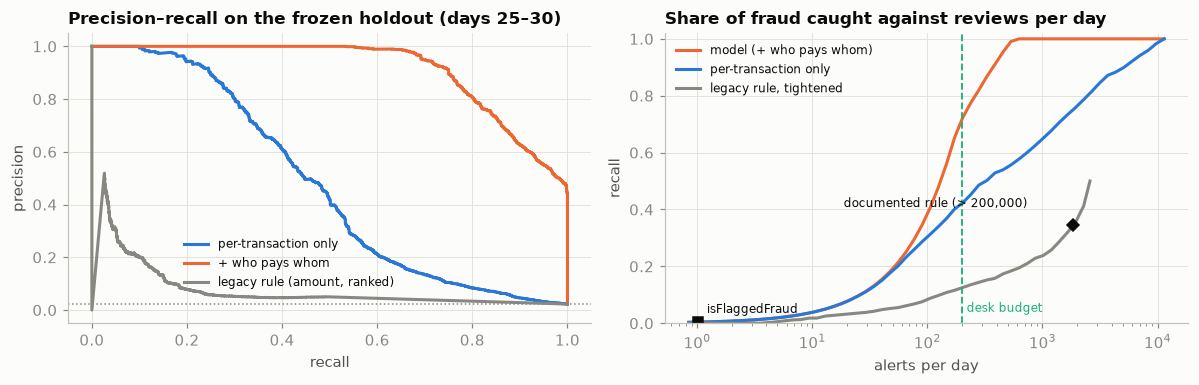

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
for p, lab_, color in [(p_base, "per-transaction only", SERIES[0]), (p_graph, "+ who pays whom", SERIES[1]),
                       (rule_score, "legacy rule (amount, ranked)", MUTED)]:
    pr, rc, _ = precision_recall_curve(y_te, p)
    ax.plot(rc, pr, lw=2, color=color, label=lab_)
ax.axhline(y_te.mean(), color=MUTED, ls=":", lw=1)
ax.set_title("Precision–recall on the frozen holdout (days 25–30)"); ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.legend(fontsize=8, loc="lower left", bbox_to_anchor=(0.2, 0.08))
ax = axes[1]
ks = np.unique(np.geomspace(5, len(y_te), 60).astype(int))
n_T = int(is_T_te.sum())
for p, lab_, color, kk in [(p_graph, "model (+ who pays whom)", SERIES[1], ks), (p_base, "per-transaction only", SERIES[0], ks),
                           (rule_score, "legacy rule, tightened", MUTED, np.r_[ks[ks < n_T], n_T])]:
    ax.plot(kk / HOLDOUT_DAYS, [precision_at_k(y_te, p, k)[1] for k in kk], lw=2, color=color, label=lab_)
ax.plot([flag.sum() / HOLDOUT_DAYS], [y_te[flag].sum() / y_te.sum()], "s", color=INK, ms=6)
ax.annotate("isFlaggedFraud", (flag.sum() / HOLDOUT_DAYS, y_te[flag].sum() / y_te.sum()), xytext=(6, 6), textcoords="offset points", fontsize=8)
ax.plot([doc.sum() / HOLDOUT_DAYS], [y_te[doc].sum() / y_te.sum()], "D", color=INK, ms=6)
ax.annotate(f"documented rule (> {LEGACY_THRESHOLD:,})", (doc.sum() / HOLDOUT_DAYS, y_te[doc].sum() / y_te.sum()), xytext=(-150, 12),
            textcoords="offset points", fontsize=8)
ax.axvline(REVIEW_BUDGET_PER_DAY, color=SERIES[2], ls="--", lw=1.2)
ax.text(REVIEW_BUDGET_PER_DAY * 1.1, 0.04, "desk budget", color=SERIES[2], fontsize=8)
ax.set_xscale("log"); ax.set_ylim(0, 1.02)
ax.set_title("Share of fraud caught against reviews per day")

def per_day_for(p, target):                    # smallest number of alerts a day that reaches the target recall
    cum = np.cumsum(y_te[np.argsort(-np.asarray(p, dtype=float), kind="stable")]) / y_te.sum()
    return (np.searchsorted(cum, target) + 1) / HOLDOUT_DAYS
print(f"alerts a day for 70 % recall · model {per_day_for(p_graph, 0.7):,.0f} · per-transaction only {per_day_for(p_base, 0.7):,.0f} · "
      f"the amount rule tops out at {y_te[is_T_te].sum() / y_te.sum():.1%} (TRANSFER legs only), "
      f"reached by reviewing every transfer: {n_T / HOLDOUT_DAYS:,.0f} a day"); ax.set_xlabel("alerts per day"); ax.set_ylabel("recall")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()

**At the same 200 alerts a day, the model's queue is 93.6 % fraud and catches 71.7 % of fraudulent transactions. The legacy rule tightened to that budget (TRANSFER ≥ 1,585,147) is 16.2 % fraud and catches 12.4 %.** The other budgets keep it honest: at the rule's own 6 flags both are perfect, which proves nothing; at the documented rule's 1,840 a day, the rule catches 34.4 % and the model all of it, at a volume no desk can review. The model reaches 70 % recall at 193 alerts a day (the per-transaction model at 1,355); the amount rule never passes 50.0 %, because it cannot see the CASH_OUT leg.

## 5 · The operating point: two hundred reviews a day

*Part B · Given model · package `chain_view`; C3 asks you to own the budget and the queue order.*

The median fraud chain moves 452,681, so at an assumed `REVIEW_COST` of 1,000 a review pays for itself if 0.22 % of reviews find fraud. Cost never binds; **capacity** does, so the decisions are staffing and the order of the queue. The threshold is set on the validation days to yield 200 a day, then frozen.

In [10]:
p_va = m_graph.predict_proba(sc.loc[va, GRAPH])[:, 1]
k_va = round(REVIEW_BUDGET_PER_DAY * VALID_DAYS)
THR = float(np.sort(p_va)[::-1][k_va - 1])
alert = p_graph >= THR
hold = sc[te].assign(score=p_graph, alert=alert)
day_tbl = hold.groupby("day").agg(transactions=("amount", "size"), fraud=("isFraud", "sum"), alerts=("alert", "sum"),
                                  caught=("isFraud", lambda s: int((s & hold.loc[s.index, "alert"]).sum())))
day_tbl["precision"] = day_tbl.caught / day_tbl.alerts.clip(lower=1)
day_tbl["recall"] = day_tbl.caught / day_tbl.fraud
print(f"threshold {THR:.3f}, set on days 18–24 to give {REVIEW_BUDGET_PER_DAY} alerts a day · on the holdout: "
      f"{alert.sum() / HOLDOUT_DAYS:.0f} alerts a day, precision {y_te[alert].mean():.1%}, recall {y_te[alert].sum() / y_te.sum():.1%}")
display(day_tbl.style.format({"transactions": "{:,}", "precision": "{:.1%}", "recall": "{:.1%}"}))

# ---- chain level: one case = a transfer and its cash-out; where is the money stopped? ----
def chain_view(alerted):
    fr = hold.assign(a=alerted)[hold.isFraud.values == 1]
    fr = fr.assign(chain=np.where(fr.type == "TRANSFER", fr.row, np.where(fr.t_partner >= 0, fr.t_partner, fr.row)),
                   aT=fr.a & (fr.type == "TRANSFER"), aC=fr.a & (fr.type == "CASH_OUT"))
    ch = fr.groupby("chain").agg(value=("amount", "max"), aT=("aT", "max"), aC=("aC", "max"))
    at_T, only_C = ch.aT.astype(bool), ch.aC.astype(bool) & ~ch.aT.astype(bool)
    return pd.Series({"chains stopped at the transfer leg": at_T.mean(), "chains stopped only at the cash-out": only_C.mean(),
                      "chains missed": 1 - at_T.mean() - only_C.mean(),
                      "fraud value stopped at the transfer leg": ch.value[at_T].sum() / ch.value.sum(),
                      "fraud value intercepted (either leg)": ch.value[at_T | only_C].sum() / ch.value.sum()}), ch

el_va = p_va * sc.amount.values[va]                                  # expected loss = score × amount
thr_el = float(np.sort(el_va)[::-1][k_va - 1])
alert_el = p_graph * hold.amount.values >= thr_el
view_model, ch = chain_view(alert)
view_el, _ = chain_view(alert_el)
view_rule, _ = chain_view(rule_score >= RULE_AT_BUDGET)
chains = pd.DataFrame({"model, by score": view_model, "model, by expected loss": view_el, "rule at the same budget": view_rule})
print(f"{len(ch):,} fraud chains in the holdout · median value {ch.value.median():,.0f} · break-even precision for one review "
      f"at REVIEW_COST = {REVIEW_COST:,}: {REVIEW_COST / ch.value.median():.2%} · expected-loss queue: "
      f"{alert_el.sum() / HOLDOUT_DAYS:.0f} alerts a day, precision {y_te[alert_el].mean():.1%}")
display(chains.style.format("{:.1%}"))

threshold 0.616, set on days 18–24 to give 200 alerts a day · on the holdout: 204 alerts a day, precision 92.9%, recall 72.6%


,transactions,fraud,alerts,caught,precision,recall
day,,,,,,
25,"24,403",240,196,180,91.8%,75.0%
26,"5,458",272,202,188,93.1%,69.1%
27,"3,722",280,207,203,98.1%,72.5%
28,"5,724",248,209,184,88.0%,74.2%
29,"23,313",260,209,185,88.5%,71.2%
30,"5,037",244,184,181,98.4%,74.2%


778 fraud chains in the holdout · median value 452,681 · break-even precision for one review at REVIEW_COST = 1,000: 0.22% · expected-loss queue: 179 alerts a day, precision 83.4%


,"model, by score","model, by expected loss",rule at the same budget
chains stopped at the transfer leg,45.6%,44.6%,24.7%
chains stopped only at the cash-out,52.8%,24.9%,0.0%
chains missed,1.5%,30.5%,75.3%
fraud value stopped at the transfer leg,74.1%,90.2%,81.1%
fraud value intercepted (either leg),97.4%,98.6%,81.1%


The frozen threshold gives 204 alerts a day on the holdout (184–209 on any day), precision 92.9 %, recall 72.6 %. The chain table shows what counting transactions hides:

- **The model finds almost every case, but often late.** It misses 1.5 % of chains but stops only 45.6 % at the transfer leg: the cash-out legs score near 1.0 through the chain link and fill the queue first.
- **By value, the old rule is better than its count.** It misses 75.3 % of chains, yet stops 81.1 % of the stolen value at the transfer leg, against the model's 74.1 %: the value sits in a few very large transfers, exactly what an amount rule catches.

Ordering by **expected loss** (score × amount, threshold set the same way) gets the best of both by value: 90.2 % stopped at the transfer leg, 98.6 % at either leg, with 179 alerts a day at 83.4 % precision. The price is in victims: it misses 30.5 % of chains, the small ones. Money recovered or victims protected is a business choice for the ADR in task C3.

In [11]:
# What the analyst opens: the evidence packet for the top-scored chain, rendered by a fixed template (no LLM)
top_c = hold[(hold.type == "CASH_OUT") & (hold.chain_back == 1)].sort_values("score", ascending=False).iloc[0]
t_leg = tx.iloc[int(top_c.t_partner)]
t_score = hold.loc[hold.row == int(top_c.t_partner), "score"].iloc[0]
packet = {"chain": f"T{int(top_c.t_partner)}", "day": int(top_c.day), "hour": int(top_c.hour),
          "transfer": {"from": f"A{int(t_leg.orig)}", "to": f"A{int(t_leg.dest)}", "amount": round(float(t_leg.amount), 2),
                       "receiver_prior_receipts": int(t_leg.dest_prior_in), "score": round(float(t_score), 3), "alerted": bool(t_score >= THR)},
          "cash_out": {"from": f"A{int(top_c.orig)}", "agent": f"A{int(top_c.dest)}", "amount": round(float(top_c.amount), 2),
                       "agent_prior_receipts": int(top_c.dest_prior_in), "score": round(float(top_c.score), 3), "alerted": bool(top_c.alert)},
          "legacy_rule": {"documented_rule_fires": bool(t_leg.amount > LEGACY_THRESHOLD), "isFlaggedFraud": int(t_leg.isFlaggedFraud)}}
note = (f"Case {packet['chain']} · day {packet['day']}, {packet['hour']:02d}:00. Account {packet['transfer']['from']} sent "
        f"{packet['transfer']['amount']:,.2f} by TRANSFER to {packet['transfer']['to']}, which had received money "
        f"{packet['transfer']['receiver_prior_receipts']} times before. In the same hour {packet['cash_out']['from']} cashed out exactly "
        f"{packet['cash_out']['amount']:,.2f} at agent {packet['cash_out']['agent']} ({packet['cash_out']['agent_prior_receipts']} earlier receipts). "
        f"Model: transfer {packet['transfer']['score']} ({'alerted' if packet['transfer']['alerted'] else 'below threshold'}), "
        f"cash-out {packet['cash_out']['score']} ({'alerted' if packet['cash_out']['alerted'] else 'below threshold'}). "
        f"Legacy rule: documented rule {'fires' if packet['legacy_rule']['documented_rule_fires'] else 'silent'}, "
        f"isFlaggedFraud = {packet['legacy_rule']['isFlaggedFraud']}.")
print(json.dumps(packet, indent=1)); print(); print(note)

{
 "chain": "T6281809",
 "day": 28,
 "hour": 3,
 "transfer": {
  "from": "A6272701",
  "to": "A9038013",
  "amount": 2054631.55,
  "receiver_prior_receipts": 0,
  "score": 0.996,
  "alerted": true
 },
 "cash_out": {
  "from": "A6272702",
  "agent": "A9038014",
  "amount": 2054631.55,
  "agent_prior_receipts": 0,
  "score": 1.0,
  "alerted": true
 },
 "legacy_rule": {
  "documented_rule_fires": true,
  "isFlaggedFraud": 0
 }
}

Case T6281809 · day 28, 03:00. Account A6272701 sent 2,054,631.55 by TRANSFER to A9038013, which had received money 0 times before. In the same hour A6272702 cashed out exactly 2,054,631.55 at agent A9038014 (0 earlier receipts). Model: transfer 0.996 (alerted), cash-out 1.0 (alerted). Legacy rule: documented rule fires, isFlaggedFraud = 0.


The hand-over to Session 10: the packet is the **context**, every field from the log or the model, and the template note traces each sentence to a field. Task S1 replaces the template with an LLM that sees only the packet; the template is its floor. Note the last line: the recorded flag stayed at 0 on a 2-million transfer to a brand-new account.

## 6 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test.*

Four shortcuts, each giving a better number and a worse system, measured against the honest model (AUPRC 0.914, precision at budget 93.6 %).

**Trap 1 — the balance columns.** The authors forbid them because fraudulent transactions are cancelled. Add them to the per-transaction model.

In [12]:
# Trap 1: the balance columns the authors say must not be used
_, p_bal, r_bal = fit_eval(BASE + BALANCES, "per-transaction + balances ⚠")
drained = (hold.amount.values == hold.oldbalanceOrg.values) & (hold.amount.values > 0)
print(f"one-line leak 'amount == sender's opening balance' on the holdout: {drained.sum():,} hits, "
      f"precision {y_te[drained].mean():.1%}, recall {y_te[drained].sum() / y_te.sum():.1%}")
# Trap 2: graph features that know the future
NAIVE_GRAPH = BASE + ["dest_total_in", "dest_prior_amt", "dest_age_steps", "chain_back", "chain_fwd"]
_, p_fut, r_fut = fit_eval(NAIVE_GRAPH, "+ whole-month graph ⚠")
print(f"fraud TRANSFERs with a same-amount CASH_OUT later in the hour: {sc.chain_fwd.values[te][is_T_te & (y_te == 1)].mean():.1%} · "
      f"legitimate TRANSFERs: {sc.chain_fwd.values[te][is_T_te & (y_te == 0)].mean():.2%}")
trap_tbl = pd.DataFrame([r_base, r_bal, r_graph, r_fut]).set_index("model")
display(trap_tbl.style.format(FMT))

one-line leak 'amount == sender's opening balance' on the holdout: 1,497 hits, precision 100.0%, recall 97.0%


fraud TRANSFERs with a same-amount CASH_OUT later in the hour: 99.2% · legitimate TRANSFERs: 0.00%


,AUPRC,ROC-AUC,precision@budget,recall@budget,fit_s
model,,,,,
per-transaction only,0.475,0.876,55.1%,42.2%,15
per-transaction + balances ⚠,0.991,1.000,100.0%,76.6%,12
+ both (who pays whom),0.914,0.997,93.6%,71.7%,9
+ whole-month graph ⚠,0.999,1.000,100.0%,76.6%,9


With the balances, the per-transaction model jumps from 0.475 to 0.991 AUPRC and fills the budget with fraud only. One equality does nearly all of it: moving exactly the sender's whole balance is fraud 100 % of the time and covers 97.0 % of fraud, because the simulator's agent always empties the account. The leakage test (C1, C4) must fail the build if a balance column, or `isFlaggedFraud`, reaches the model.

**Trap 2 — the graph that knows the future.** Build the graph on the whole month, as Task 01 did, and two features change meaning: the receiver's *total* receipts count payments not yet made, and the *forward* chain link marks a TRANSFER because a same-amount CASH_OUT follows later in the hour (99.2 % of fraudulent TRANSFERs, 0.00 % of legitimate ones). The model rises to 0.999 and 100 % precision at budget, none of it available at authorisation. An end-of-hour batch could see the cash-out, after the money has gone (task S2).

**Trap 3 — the simulator's clock.** Fraud arrives at the same rate every hour while legitimate traffic sleeps (Section 7). Remove the hour; then add a counter of transactions so far in the hour, since a quiet hour here is mostly fraud.

**Trap 4 — the fraud-only tail.** The card's holdout runs to step 744, but steps 719–743 hold 296 scored transactions, all fraud, like Task 01's laundering-only tail.

In [13]:
# Trap 3: the simulator's clock
_, p_noclock, r_noclock = fit_eval([c for c in GRAPH if c != "hour"], "+ who pays whom, no hour")
_, p_traffic, r_traffic = fit_eval(GRAPH + ["traffic_so_far"], "+ who pays whom + traffic counter ⚠")
# Trap 4: the fraud-only tail inside the card's holdout (steps 577–743)
tail = tx[tx.type.isin(SCORED_TYPES) & (tx.step > LAST_STEP)].copy()
tail["type"] = pd.Categorical(tail.type.astype(str), categories=sc.type.cat.categories)
p_tail = m_graph.predict_proba(tail[GRAPH])[:, 1]
y_long, p_long = np.r_[y_te, tail.isFraud.values], np.r_[p_graph, p_tail]
k_long = round(REVIEW_BUDGET_PER_DAY * (int(tx.step.max()) - VALID_END) / 24)
pk_long, rk_long = precision_at_k(y_long, p_long, k_long)
r_tail = {"model": "+ both, holdout to step 743 ⚠", "AUPRC": average_precision_score(y_long, p_long),
          "ROC-AUC": roc_auc_score(y_long, p_long), "precision@budget": pk_long, "recall@budget": rk_long, "fit_s": 0}
print(f"tail: {len(tail)} rows, {tail.isFraud.mean():.0%} fraud · holdout base rate {y_te.mean():.2%} → {y_long.mean():.2%} with the tail · "
      f"legacy rule tightened to the budget, precision {y_te[rule_score >= RULE_AT_BUDGET].mean():.1%} → "
      f"{precision_at_k(y_long, np.r_[rule_score, np.where(tail.type == 'TRANSFER', tail.amount, -1.0)], k_long)[0]:.1%} with the tail")
display(pd.DataFrame([r_graph, r_noclock, r_traffic, r_tail]).set_index("model").style.format(FMT))

tail: 296 rows, 100% fraud · holdout base rate 2.28% → 2.71% with the tail · legacy rule tightened to the budget, precision 16.2% → 17.4% with the tail


,AUPRC,ROC-AUC,precision@budget,recall@budget,fit_s
model,,,,,
+ both (who pays whom),0.914,0.997,93.6%,71.7%,9
"+ who pays whom, no hour",0.847,0.995,81.8%,62.7%,9
+ who pays whom + traffic counter ⚠,0.946,0.998,98.6%,75.6%,11
"+ both, holdout to step 743 ⚠",0.923,0.997,94.7%,71.6%,0


Without the hour, the model falls from 0.914 to 0.847 AUPRC and from 93.6 % to 81.8 % precision at budget; with the counter it rises to 0.946 and 98.6 %. Night-time risk is real, so the hour is defensible, but its strength here is the simulator's flat fraud clock: report the clock-free number next to the headline (81.8 % still beats the rule's 16.2 %) and keep the counter out. The tail lies the same way: its 296 sure frauds lift the base rate from 2.28 % to 2.71 %, AUPRC to 0.923 and precision at budget to 94.7 % (the rule's to 17.4 %), enough to move a gate set near its threshold.

# Part C — Productionise it

*Sections 7–10: this is your assignment.*

## 7 · After deployment: traffic switches off, fraud does not, and a new path arrives (simulated)

*Part C · Productionise · what your monitoring plan must catch (C5, E4); reuse `psi` and `psi_shares`.*

Freeze the model on day 17 and the threshold on day 24 (Section 5), and run them over days 18–30, on two clocks as in Task 02: **now** (inputs, scores, alerts, the leg mix of the queue) and **later** (precision and recall, once confirmed). Then the drill: we **simulate a new fraud path** by training a second model as if fraud had never used the TRANSFER leg. PaySim has no such change; the simulation is ours and labelled wherever it appears.

fraud rate by hour (training days): 0.03% at 18:00 · 21.3% at 04:00


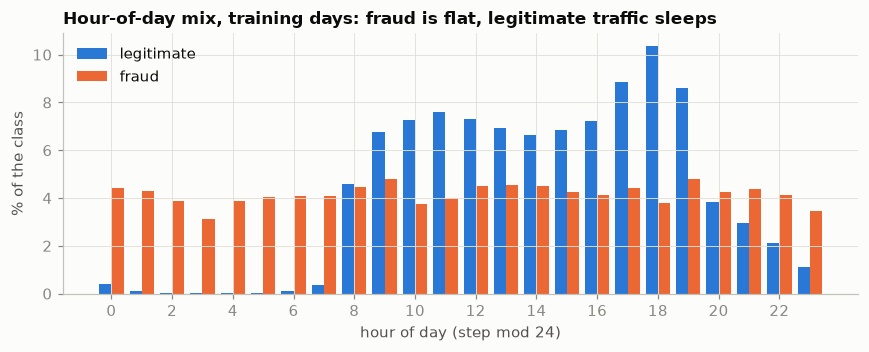

In [14]:
hour_mix = tx[tx.step <= TRAIN_END].groupby(["hour", "isFraud"]).size().unstack()
share = hour_mix / hour_mix.sum()
rate = hour_mix[1] / hour_mix.sum(axis=1)
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.bar(share.index - 0.2, share[0] * 100, width=0.4, color=SERIES[0], label="legitimate")
ax.bar(share.index + 0.2, share[1] * 100, width=0.4, color=SERIES[1], label="fraud")
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hour of day (step mod 24)"); ax.set_ylabel("% of the class")
ax.set_title("Hour-of-day mix, training days: fraud is flat, legitimate traffic sleeps"); ax.legend(loc="upper left")
plt.tight_layout()
print(f"fraud rate by hour (training days): {rate.min():.2%} at {int(rate.idxmin()):02d}:00 · {rate.max():.1%} at {int(rate.idxmax()):02d}:00")

input PSI on busy training days: hour ≤ 0.12, amount ≤ 0.05 · days 18–30: hour 0.92–3.46, amount 0.00–0.03
days 18–30 · alerts ÷ budget 0.86–1.14 · precision 0.77–0.98 · score PSI 0.06–0.39 · TRANSFER share of alerts 0.28–0.44 (new-path model 0.01–0.06) · TRANSFER-leg recall 0.35–0.51 (new-path model 0.02–0.10) · CASH_OUT-leg recall, new-path model 1.00–1.00


,psi_score,alerts_per_budget,transfer_share_alerts,transfer_share_alerts_new,precision,transfer_leg_recall,transfer_leg_recall_new,cash_out_leg_recall_new
day,,,,,,,,
18,0.065,1.130,0.416,0.054,0.889,0.515,0.097,1.0
20,0.278,0.900,0.344,0.035,0.956,0.458,0.051,1.0
22,0.301,1.140,0.439,0.063,0.768,0.367,0.047,1.0
24,0.388,0.960,0.276,0.023,0.979,0.350,0.036,1.0
26,0.190,1.010,0.332,0.041,0.931,0.390,0.037,1.0
28,0.190,1.045,0.411,0.029,0.880,0.492,0.048,1.0
30,0.345,0.920,0.342,0.054,0.984,0.492,0.082,1.0


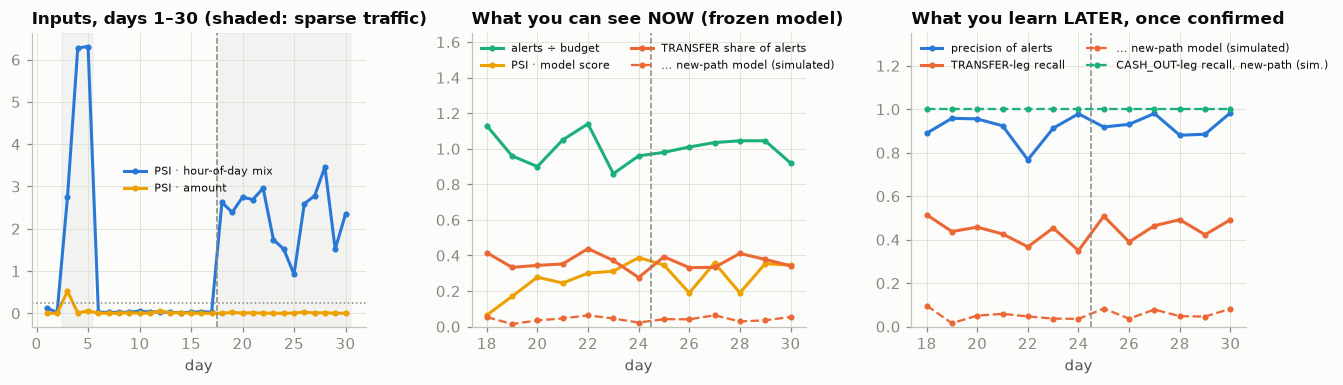

In [15]:
def psi_shares(ref_counts, cur_counts):
    r = ref_counts / ref_counts.sum() + 1e-6
    c = cur_counts / cur_counts.sum() + 1e-6
    return float(np.sum((c - r) * np.log(c / r)))

def psi(ref, cur, bins=10):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    return psi_shares(np.histogram(ref, edges)[0].astype(float), np.histogram(cur, edges)[0].astype(float))

ref = tr & keep                                                # a uniform 10 % of the training rows: the reference set
ref_hour = np.bincount(sc.hour.values[ref], minlength=24).astype(float)
ref_amount = np.log1p(sc.amount.values[ref])
ref_score = m_graph.predict_proba(sc.loc[ref, GRAPH])[:, 1]
inputs = sc.groupby("day").apply(lambda d: pd.Series({
    "psi_hour": psi_shares(ref_hour, np.bincount(d.hour.values, minlength=24).astype(float)),
    "psi_amount": psi(ref_amount, np.log1p(d.amount.values)),
    "transactions": len(d)}), include_groups=False)

# SIMULATED new fraud path: a second model trained as if fraud had never used the TRANSFER leg
held_out = trs & ~((sc.isFraud.values == 1) & (sc.type.values == "TRANSFER"))
m_new = lgb.LGBMClassifier(**LGB_PARAMS).fit(sc.loc[held_out, GRAPH], sc.isFraud.values[held_out])
stream = ~tr                                                   # days 18–30, scored by the frozen models
p_stream = m_graph.predict_proba(sc.loc[stream, GRAPH])[:, 1]
p_new = m_new.predict_proba(sc.loc[stream, GRAPH])[:, 1]
thr_new = float(np.sort(p_new[va[stream]])[::-1][k_va - 1])   # same budget rule, same validation days
s = sc[stream].assign(p=p_stream, alert=p_stream >= THR, p_new=p_new, alert_new=p_new >= thr_new)
s["fraud_T"] = (s.isFraud == 1) & (s.type == "TRANSFER")
s["fraud_C"] = (s.isFraud == 1) & (s.type == "CASH_OUT")
mon = s.groupby("day").apply(lambda d: pd.Series({
    "psi_score": psi(ref_score, d.p.values),
    "alerts_per_budget": d.alert.sum() / REVIEW_BUDGET_PER_DAY,
    "transfer_share_alerts": (d.type[d.alert] == "TRANSFER").mean(),
    "transfer_share_alerts_new": (d.type[d.alert_new] == "TRANSFER").mean(),
    "precision": d.isFraud[d.alert].mean(),
    "transfer_leg_recall": (d.alert & d.fraud_T).sum() / d.fraud_T.sum(),
    "transfer_leg_recall_new": (d.alert_new & d.fraud_T).sum() / d.fraud_T.sum(),
    "cash_out_leg_recall_new": (d.alert_new & d.fraud_C).sum() / d.fraud_C.sum(),
}), include_groups=False)

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6))
ax = axes[0]
ax.plot(inputs.index, inputs.psi_hour, "-o", ms=3, lw=2, color=SERIES[0], label="PSI · hour-of-day mix")
ax.plot(inputs.index, inputs.psi_amount, "-o", ms=3, lw=2, color=SERIES[3], label="PSI · amount")
for a, b in [(2.5, 5.5), (17.5, 30.5)]:
    ax.axvspan(a, b, color=MUTED, alpha=0.08)
ax.axhline(0.25, color=MUTED, ls=":", lw=1); ax.axvline(TRAIN_END / 24 + 0.5, color=MUTED, ls="--", lw=1)
ax.set_title("Inputs, days 1–30 (shaded: sparse traffic)"); ax.set_xlabel("day"); ax.legend(fontsize=7, loc="center")
ax = axes[1]
ax.plot(mon.index, mon.alerts_per_budget, "-o", ms=3, lw=2, color=SERIES[2], label="alerts ÷ budget")
ax.plot(mon.index, mon.psi_score, "-o", ms=3, lw=2, color=SERIES[3], label="PSI · model score")
ax.plot(mon.index, mon.transfer_share_alerts, "-o", ms=3, lw=2, color=SERIES[1], label="TRANSFER share of alerts")
ax.plot(mon.index, mon.transfer_share_alerts_new, "--o", ms=3, lw=1.5, color=SERIES[1], label="… new-path model (simulated)")
ax.axvline(VALID_END / 24 + 0.5, color=MUTED, ls="--", lw=1); ax.set_ylim(0, 1.65)
ax.set_title("What you can see NOW (frozen model)"); ax.set_xlabel("day"); ax.legend(fontsize=7, loc="upper left", ncol=2)
ax = axes[2]
ax.plot(mon.index, mon.precision, "-o", ms=3, lw=2, color=SERIES[0], label="precision of alerts")
ax.plot(mon.index, mon.transfer_leg_recall, "-o", ms=3, lw=2, color=SERIES[1], label="TRANSFER-leg recall")
ax.plot(mon.index, mon.transfer_leg_recall_new, "--o", ms=3, lw=1.5, color=SERIES[1], label="… new-path model (simulated)")
ax.plot(mon.index, mon.cash_out_leg_recall_new, "--o", ms=3, lw=1.5, color=SERIES[2], label="CASH_OUT-leg recall, new-path (sim.)")
ax.axvline(VALID_END / 24 + 0.5, color=MUTED, ls="--", lw=1); ax.set_ylim(0, 1.35)
ax.set_title("What you learn LATER, once confirmed"); ax.set_xlabel("day"); ax.legend(fontsize=7, loc="upper left", ncol=2)
plt.tight_layout()
print(f"input PSI on busy training days: hour ≤ {inputs.psi_hour[busy[:30]].max():.2f}, amount ≤ {inputs.psi_amount[busy[:30]].max():.2f} · "
      f"days 18–30: hour {inputs.psi_hour.loc[18:].min():.2f}–{inputs.psi_hour.loc[18:].max():.2f}, "
      f"amount {inputs.psi_amount.loc[18:].min():.2f}–{inputs.psi_amount.loc[18:].max():.2f}")
rng_ = lambda col: f"{mon[col].min():.2f}–{mon[col].max():.2f}"
print(f"days 18–30 · alerts ÷ budget {rng_('alerts_per_budget')} · precision {rng_('precision')} · score PSI {rng_('psi_score')} · "
      f"TRANSFER share of alerts {rng_('transfer_share_alerts')} (new-path model {rng_('transfer_share_alerts_new')}) · "
      f"TRANSFER-leg recall {rng_('transfer_leg_recall')} (new-path model {rng_('transfer_leg_recall_new')}) · "
      f"CASH_OUT-leg recall, new-path model {rng_('cash_out_leg_recall_new')}")
display(mon.round(3).iloc[::2])

The fraud rate by hour runs from 0.03 % at 18:00 to 21.3 % at 04:00: the clock of Trap 3. Read the three panels from left to right.

- **The hour mix drifts and never returns; amounts do not move.** Hour-mix PSI is ≤ 0.12 on busy training days, higher still on the sparse days 3–5, and 0.92–3.46 on every day from 18; amount PSI stays at 0.00–0.03. This is Task 02 in reverse: there nothing moved and the model went blind; here the hour mix moves every day and the model is fine (0.86–1.14 times the budget, precision 77–98 %), while the score PSI wanders between 0.06 and 0.39. An hour-mix alarm would page someone daily for a traffic change, so the plan must say it triggers a queue check, not a retrain.
- **The new path (simulated) shows now, without labels, in the leg mix.** TRANSFERs are 28–44 % of the full model's alerts and 1–6 % of the new-path model's; the alert count holds because cash-out legs refill the queue.
- **Later, the cost.** The new-path model's TRANSFER-leg recall falls from 35–51 % to 2–10 %. It still catches every CASH_OUT leg, so cases are found, but after the money has left the victim. For C5: monitor the leg mix against a band from the validation days, and keep the legacy rule as a canary on the transfer leg.

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The ten principles every project covers, updated with what this notebook measured.

In [16]:
holdout_fp = hashlib.sha256(pd.util.hash_pandas_object(sc.loc[te, ["step", "type", "amount", "orig", "dest", "isFraud"]], index=False).values.tobytes()).hexdigest()
print(f"holdout fingerprint (SHA-256 of steps {VALID_END + 1}–{LAST_STEP}, {te.sum():,} rows): {holdout_fp[:16]}…")
print(f"features in the model: {GRAPH}")
print(f"excluded on purpose: {BALANCES + ['isFlaggedFraud', 'dest_total_in', 'chain_fwd', 'traffic_so_far']}")

holdout fingerprint (SHA-256 of steps 577–718, 67,657 rows): 90522dbce4704aae…
features in the model: ['type', 'amount', 'hour', 'dest_prior_in', 'dest_prior_amt', 'dest_age_steps', 'chain_back']
excluded on purpose: ['oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'isFlaggedFraud', 'dest_total_in', 'chain_fwd', 'traffic_so_far']


| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/momo_fraud/` (`features.py`: as-of counters, chain link; `rules.py`: the legacy rule, documented and tightened); `POST /score` per transaction; compose with Postgres for counters and predictions |
| Monitoring (S04) | Alerts a day against 200 (0.86–1.14×; alarm above 1.5×); queue precision once confirmed (77–98 %); hour-mix PSI as a *traffic* signal (≤ 0.12 on busy days, 0.92–3.46 from day 18); TRANSFER share of alerts in a 0.28–0.44 band (0.01–0.06 on the simulated path); latency |
| CI/CD gate (S05) | Precision at budget (k = 1,183) on steps 577–718, SHA-256 `90522dbce4704aae…`: 93.6 % today; fail below 85 % (a clock-free model, at 81.8 %, needs an ADR). Leakage test on the balance columns and `isFlaggedFraud`; as-of test on the receiver counters |
| MLflow tracking and registry (S06) | Step windows, features with the excluded columns named, `NEG_SAMPLE`, threshold 0.616, budget, the legacy rule on the same window (16.2 % precision, 12.4 % recall), fingerprints; `champion` and `challenger` aliases |
| Offline / online training and serving | Online scoring with hold and review (the cash-out follows within the hour); daily rolling retraining against the static day-17 model |
| Data and model drift | Traffic regime: legitimate volume 349 k–574 k → 760–57,613 a day, fraud steady at about 262. New path (simulated): TRANSFER-leg recall 35–51 % → 2–10 %, visible now in the leg mix |
| Knowledge base and context (S07–S09) | Who-pays-whom graph (152,376 components among 313,506 accounts in the holdout window), type ontology, the mule link as entity resolution. Ablation AUPRC: 0.475 → 0.560 (receiver) → 0.761 (chain) → 0.914 (both) |
| GenAI and context engineering (S10–S11) | Case note from the chain's evidence packet only; golden set of labelled chains and look-alikes; the template note as the floor |
| Governance | Synthetic, CC BY-SA 4.0 (derived data is share-alike); surrogate keys on load; the model card names the simulator's artefacts and the forbidden columns |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](../../docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap, with a test.** A leakage test for the balance columns and `isFlaggedFraud`; an as-of test that recomputes the graph features on a stream truncated at a random step and checks earlier rows do not change (it catches `dest_total_in` and `chain_fwd`); the tail cut; a decision on the hour, with the clock-free number.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary `REVIEW_BUDGET_PER_DAY` (50–1,000) and `REVIEW_COST`; compare score order with expected-loss order on chains and value stopped at the transfer leg; write the ADR that names the order and who signed it off.
- **C4 — Package, container, CI gate.** `src/momo_fraud/`, `POST /score`, compose with Postgres; `make ci` gates on precision at budget on steps 577–718, checks the fingerprint, and fails on the leakage or as-of test (Sessions 02, 03, 05).
- **C5 — Register, document, monitor.** MLflow runs logging the excluded columns and the rule's score on the same window; a `champion`; the model card (synthetic provenance, the three artefacts, the regime change); a monitoring plan with the leg-mix signal, the hour-mix PSI as a traffic alarm, the confirmation delay and the retraining trigger (Sessions 04, 06).

### Extension

- **E1 — Knowledge-base ablation.** Model accounts, roles (customer, merchant, agent, mule) and transaction types as a small ontology with SHACL shapes, build the graph from it with the mule link as an inferred relation, and run the ablation at budgets of 50–1,000 a day (Sessions 07–09).
- **E2 — Governance and errors by group.** With no protected attributes, ask who bears the false alerts: false-alert rate by amount band and by hour (night users). Check the EU AI Act's Annex III creditworthiness item and its fraud-detection carve-out, and put the obligations you think remain to compliance as questions.
- **E3 — Rolling retraining.** Retrain daily with a one-to-three-day confirmation delay; compare with the static day-17 model over days 18–30 at the same budget.
- **E4 — Detect the new path without labels.** Leg-mix band, rule–model disagreement, cash-out alerts with an unalerted transfer: which fires first in the simulated drill?

### Stretch

- **S1 — Investigator case note (GenAI).** Generate the note from the evidence packet only (versioned prompt, structured output citing packet fields); evaluate on a golden set of 50 labelled chains and 20 legitimate look-alikes for factuality, test a prompt injection through a packet field, and report the cost per note (Sessions 10–11).
- **S2 — Online scoring and its cost.** Serve the features from a store (receiver counters, an index of the last hour's transfers by amount), replay the holdout as a stream, and measure latency against the authorisation budget and cost per thousand transactions. Decide in an ADR whether an end-of-hour batch using the forward link is worth the money that leaves meanwhile.
- **S3 — Hand-over to the legacy engine.** Specify how the model's alerts reach the existing rule engine's case queue (message schema, idempotency, what happens when the model is down) and test the fallback to the tightened rule at the same budget.

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Session 02 layout; fresh-clone test passes; `data/` not committed; account names never past the loader
- [ ] `README.md` states the windows, the sampling rule and how to obtain the data (Kaggle, CC BY-SA 4.0)
- [ ] Forward evaluation only; leakage and as-of tests in the suite; tail cut
- [ ] Legacy rule scored on the same window and budget, by count and by value
- [ ] Operating point and queue order from capacity, with the ADR
- [ ] CI gate against the fingerprinted holdout; registered model with model card; monitoring plan
- [ ] One-page recommendation to the head of fraud, with the clock-free number
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `scikit-learn`, `lightgbm`, `networkx`, `matplotlib`, `kagglehub` (pinned in `requirements.txt`).
- López-Rojas, E. A., Elmir, A., Axelsson, S. (2016). *PaySim: A financial mobile money simulator for fraud detection.* 28th European Modeling and Simulation Symposium (EMSS), Larnaca.
- Lopez-Rojas, E. *Synthetic Financial Datasets For Fraud Detection*, Kaggle `ealaxi/paysim1` (CC BY-SA 4.0), with the authors' notes on the balance columns and on `isFlaggedFraud`.
- Kaufman, S., Rosset, S., Perlich, C. (2012). *Leakage in Data Mining: Formulation, Detection, and Avoidance.* ACM TKDD.
- Ke, G. et al. (2017). *LightGBM: A Highly Efficient Gradient Boosting Decision Tree.* NeurIPS. Hagberg, A., Schult, D., Swart, P. (2008). *Exploring Network Structure, Dynamics, and Function using NetworkX.* SciPy.
- Huyen, C. (2022). *Designing Machine Learning Systems*, Ch. 5 (feature engineering: leakage) and Ch. 8 (distribution shifts and monitoring).

In [17]:
print(f"pandas {pd.__version__} · numpy {np.__version__} · pyarrow {pa.__version__} · lightgbm {lgb.__version__} · "
      f"networkx {nx.__version__} · scikit-learn {sklearn.__version__}")
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

pandas 3.1.0 · numpy 2.5.4 · pyarrow 26.0.0 · lightgbm 4.7.0 · networkx 3.7 · scikit-learn 1.9.1
notebook finished · total wall time 186s
